# Análise de Logs PX4 - Rate Controller

Este notebook replica as curvas do QGroundControl para análise de PID.

In [16]:
# Instalar dependências (rodar uma vez)
# !pip install pyulog pandas matplotlib

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from pyulog import ULog
from pyulog.px4 import PX4ULog
import numpy as np

In [18]:
# Lista os logs disponíveis
import glob

log_files = sorted(glob.glob("px4_logs/**/*.ulg", recursive=True))
print("Logs disponíveis:")
for i, f in enumerate(log_files):
    print(f"  [{i}] {f}")

# Seleciona o log (mude o índice aqui)
LOG_INDEX = 0
LOG_FILE = log_files[LOG_INDEX]
print(f"\n>>> Usando: {LOG_FILE}")

ulog = ULog(LOG_FILE)
px4 = PX4ULog(ulog)

print(f"Duração do log: {(ulog.last_timestamp - ulog.start_timestamp) / 1e6:.1f} segundos")
print(f"\nTópicos disponíveis:")
for d in ulog.data_list:
    print(f"  - {d.name} ({len(d.data['timestamp'])} amostras)")

Logs disponíveis:
  [0] px4_logs/Hermit/07_09_2024/log_0_2024-9-7-15-13-48.ulg
  [1] px4_logs/Hermit/07_09_2024/log_1_2024-9-7-15-19-36.ulg
  [2] px4_logs/Hermit/07_09_2024/log_2_2024-9-7-15-23-14.ulg
  [3] px4_logs/Hermit/07_09_2024/log_3_2024-9-7-15-24-34.ulg
  [4] px4_logs/Hermit/07_09_2024/log_4_2024-9-7-15-34-16.ulg
  [5] px4_logs/Hermit/07_09_2024/log_5_2024-9-7-15-38-50.ulg
  [6] px4_logs/Hermit/07_09_2024/log_6_2024-9-7-15-42-54.ulg
  [7] px4_logs/Hermit/14_09_2024/teste-offboard/teste-1/log_2_2024-9-14-11-35-14.ulg
  [8] px4_logs/Hermit/14_09_2024/teste-offboard/teste-2-pouso_espiral/log_0_UnknownDate.ulg
  [9] px4_logs/Hermit/14_09_2024/teste-offboard/teste-3-pouso_off/log_1_2024-9-14-14-35-26.ulg
  [10] px4_logs/Hermit/14_09_2024/teste-offboard/ultimos-testes-offboard/log_0_2024-9-14-15-23-42.ulg
  [11] px4_logs/Hermit/14_09_2024/teste-offboard/ultimos-testes-offboard/log_10_2024-9-14-15-53-18.ulg
  [12] px4_logs/Hermit/14_09_2024/teste-offboard/ultimos-testes-offboard/log_1

In [19]:
def get_data(ulog, topic_name):
    """Extrai um tópico do ULog como DataFrame."""
    for d in ulog.data_list:
        if d.name == topic_name:
            df = pd.DataFrame(d.data)
            df['time_s'] = (df['timestamp'] - ulog.start_timestamp) / 1e6
            return df
    return None

## Dados do Rate Controller

O que entra no rate controller:
- **Setpoint**: `vehicle_rates_setpoint` (roll, pitch, yaw em rad/s)
- **Medido**: `vehicle_angular_velocity` (gyro)
- **Saída**: `actuator_controls_0` ou `rate_ctrl_status`

In [20]:
# Extrai os dados principais
rates_sp = get_data(ulog, 'vehicle_rates_setpoint')      # Setpoint (desejado)
angular_vel = get_data(ulog, 'vehicle_angular_velocity') # Medido (gyro)
rate_status = get_data(ulog, 'rate_ctrl_status')         # Status do controlador

print("Colunas em vehicle_rates_setpoint:")
if rates_sp is not None:
    print(rates_sp.columns.tolist())

print("\nColunas em vehicle_angular_velocity:")
if angular_vel is not None:
    print(angular_vel.columns.tolist())

Colunas em vehicle_rates_setpoint:
['timestamp', 'roll', 'pitch', 'yaw', 'thrust_body[0]', 'thrust_body[1]', 'thrust_body[2]', 'reset_integral', 'time_s']

Colunas em vehicle_angular_velocity:
['timestamp', 'timestamp_sample', 'xyz[0]', 'xyz[1]', 'xyz[2]', 'xyz_derivative[0]', 'xyz_derivative[1]', 'xyz_derivative[2]', 'time_s']


In [21]:
def plot_rate_response(rates_sp, angular_vel, axis='roll', time_range=None):
    """
    Plota setpoint vs medido para um eixo (como o QGC faz).
    
    axis: 'roll', 'pitch', ou 'yaw'
    time_range: tupla (t_inicio, t_fim) em segundos, ou None para tudo
    """
    # Mapeia eixo para coluna
    axis_map = {'roll': 0, 'pitch': 1, 'yaw': 2}
    idx = axis_map[axis]
    
    # Colunas podem ser 'xyz[0]' ou 'roll/pitch/yaw'
    sp_col = axis if axis in rates_sp.columns else f'xyz[{idx}]'
    vel_col = axis if axis in angular_vel.columns else f'xyz[{idx}]'
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    
    # Converte rad/s para deg/s
    sp_deg = np.rad2deg(rates_sp[sp_col])
    vel_deg = np.rad2deg(angular_vel[vel_col])
    
    # Aplica range de tempo
    if time_range:
        sp_mask = (rates_sp['time_s'] >= time_range[0]) & (rates_sp['time_s'] <= time_range[1])
        vel_mask = (angular_vel['time_s'] >= time_range[0]) & (angular_vel['time_s'] <= time_range[1])
    else:
        sp_mask = slice(None)
        vel_mask = slice(None)
    
    # Plot superior: Setpoint vs Medido
    ax1.plot(rates_sp['time_s'][sp_mask], sp_deg[sp_mask], 'b-', label='Setpoint', alpha=0.8)
    ax1.plot(angular_vel['time_s'][vel_mask], vel_deg[vel_mask], 'r-', label='Medido', alpha=0.6)
    ax1.set_ylabel(f'{axis.upper()} Rate (deg/s)')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_title(f'Rate Controller - {axis.upper()}')
    
    # Plot inferior: Erro
    # Interpola para mesmo tempo
    common_time = rates_sp['time_s'][sp_mask].values
    vel_interp = np.interp(common_time, angular_vel['time_s'], vel_deg)
    error = sp_deg[sp_mask].values - vel_interp
    
    ax2.plot(common_time, error, 'g-', alpha=0.8)
    ax2.axhline(y=0, color='k', linestyle='--', alpha=0.3)
    ax2.set_ylabel('Erro (deg/s)')
    ax2.set_xlabel('Tempo (s)')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    return fig

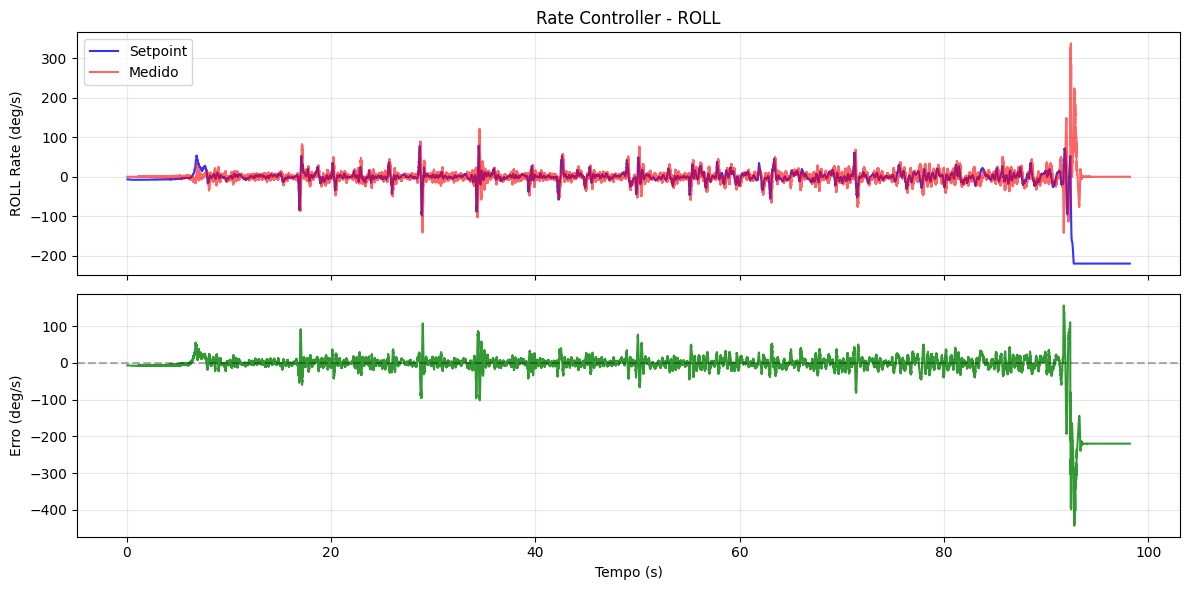

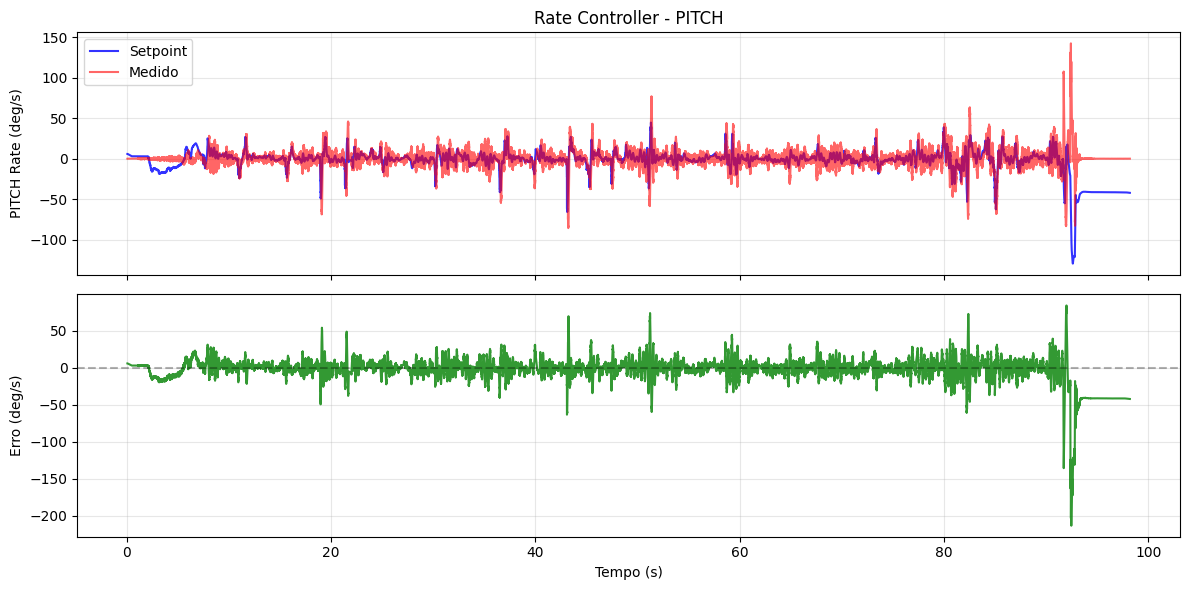

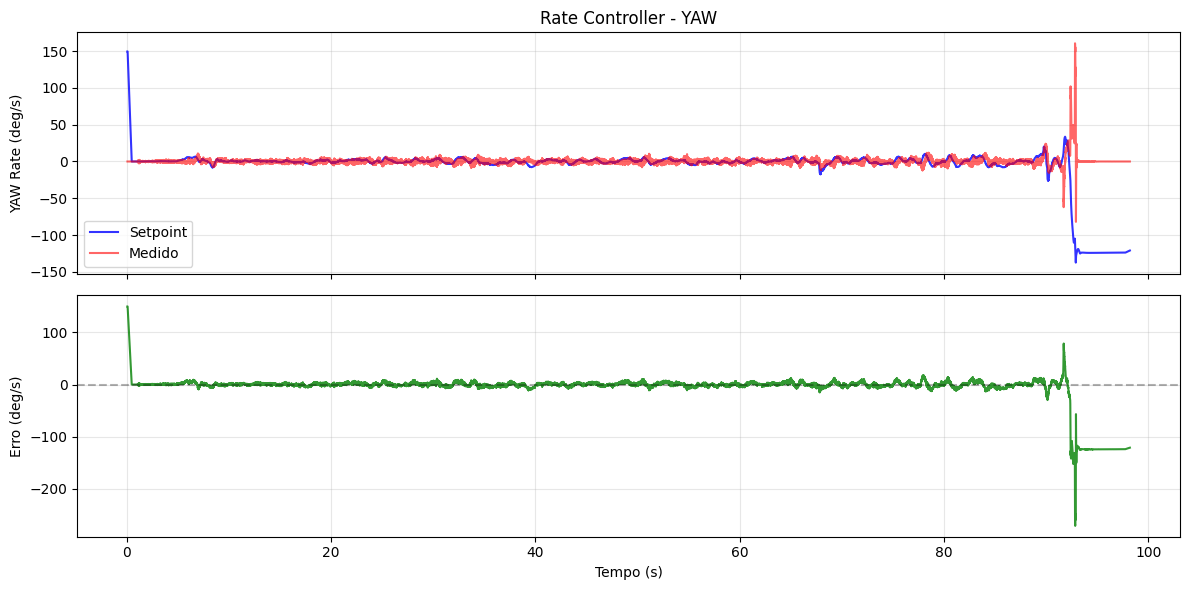

In [22]:
# Plota os 3 eixos
if rates_sp is not None and angular_vel is not None:
    for axis in ['roll', 'pitch', 'yaw']:
        try:
            plot_rate_response(rates_sp, angular_vel, axis=axis)
            plt.show()
        except Exception as e:
            print(f"Erro plotando {axis}: {e}")

## Zoom em um trecho específico

Para analisar a resposta ao degrau, faça zoom em um intervalo de tempo.

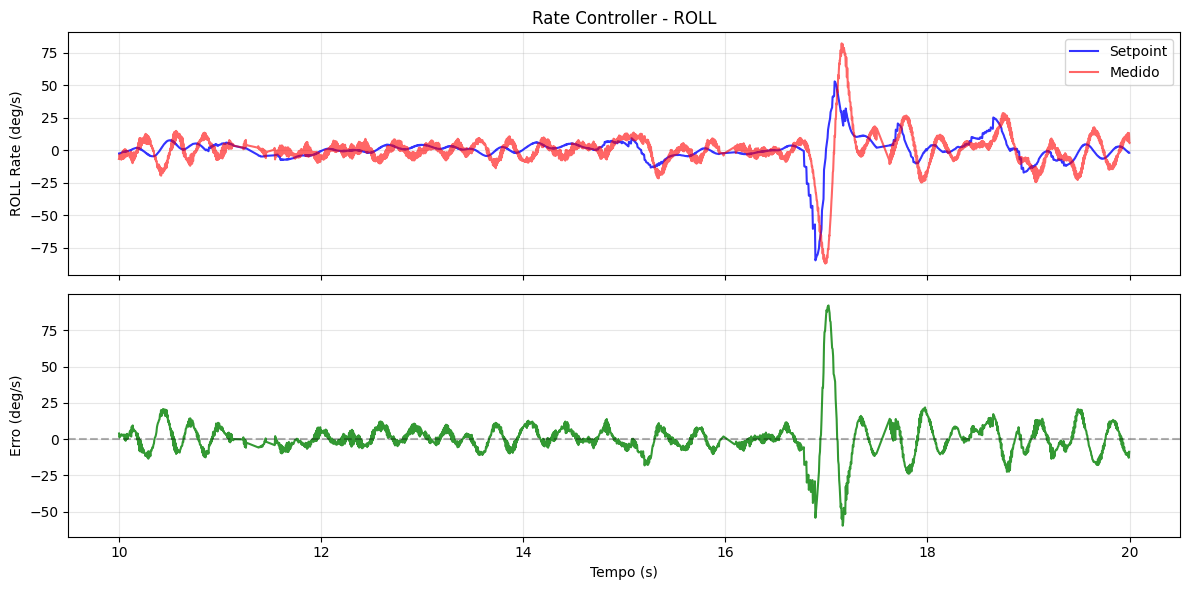

In [23]:
# Exemplo: zoom entre 10s e 20s no eixo roll
if rates_sp is not None and angular_vel is not None:
    plot_rate_response(rates_sp, angular_vel, axis='roll', time_range=(10, 20))
    plt.show()

## Métricas de Desempenho do PID

In [24]:
def calc_pid_metrics(rates_sp, angular_vel, axis='roll'):
    """Calcula métricas de desempenho do controlador."""
    axis_map = {'roll': 0, 'pitch': 1, 'yaw': 2}
    idx = axis_map[axis]
    
    sp_col = axis if axis in rates_sp.columns else f'xyz[{idx}]'
    vel_col = axis if axis in angular_vel.columns else f'xyz[{idx}]'
    
    # Interpola para mesmo tempo
    common_time = rates_sp['time_s'].values
    vel_interp = np.interp(common_time, angular_vel['time_s'], angular_vel[vel_col])
    sp = rates_sp[sp_col].values
    
    error = sp - vel_interp
    error_deg = np.rad2deg(error)
    
    metrics = {
        'MAE (deg/s)': np.mean(np.abs(error_deg)),
        'RMSE (deg/s)': np.sqrt(np.mean(error_deg**2)),
        'Max Error (deg/s)': np.max(np.abs(error_deg)),
        'Std Error (deg/s)': np.std(error_deg),
    }
    return metrics

if rates_sp is not None and angular_vel is not None:
    for axis in ['roll', 'pitch', 'yaw']:
        try:
            metrics = calc_pid_metrics(rates_sp, angular_vel, axis)
            print(f"\n{axis.upper()}:")
            for k, v in metrics.items():
                print(f"  {k}: {v:.2f}")
        except Exception as e:
            print(f"Erro calculando {axis}: {e}")


ROLL:
  MAE (deg/s): 24.11
  RMSE (deg/s): 58.41
  Max Error (deg/s): 443.70
  Std Error (deg/s): 56.94

PITCH:
  MAE (deg/s): 11.21
  RMSE (deg/s): 18.93
  Max Error (deg/s): 213.81
  Std Error (deg/s): 18.68

YAW:
  MAE (deg/s): 10.27
  RMSE (deg/s): 31.31
  Max Error (deg/s): 270.78
  Std Error (deg/s): 30.51


## Parâmetros PID do Log

In [25]:
# Mostra parâmetros PID salvos no log
pid_params = ['MC_ROLLRATE_P', 'MC_ROLLRATE_I', 'MC_ROLLRATE_D', 'MC_ROLLRATE_K',
              'MC_PITCHRATE_P', 'MC_PITCHRATE_I', 'MC_PITCHRATE_D', 'MC_PITCHRATE_K',
              'MC_YAWRATE_P', 'MC_YAWRATE_I', 'MC_YAWRATE_D', 'MC_YAWRATE_K']

print("Parâmetros PID do Rate Controller:")
print("-" * 40)
for param_name, param_value in ulog.initial_parameters.items():
    if param_name in pid_params:
        print(f"{param_name}: {param_value}")

Parâmetros PID do Rate Controller:
----------------------------------------
MC_PITCHRATE_D: 0.002199999988079071
MC_PITCHRATE_I: 0.17499999701976776
MC_PITCHRATE_K: 0.44999998807907104
MC_PITCHRATE_P: 0.21677786111831665
MC_ROLLRATE_D: 0.0017999999690800905
MC_ROLLRATE_I: 0.20000000298023224
MC_ROLLRATE_K: 0.4000000059604645
MC_ROLLRATE_P: 0.2151256948709488
MC_YAWRATE_D: 0.0035454528406262398
MC_YAWRATE_I: 0.1599999964237213
MC_YAWRATE_K: 1.75
MC_YAWRATE_P: 0.1544198989868164


## Mimetizando o Rate Setpoint do PX4

O **Attitude Controller** do PX4 gera o rate setpoint usando um controlador proporcional sobre o erro de atitude:

```
rate_sp = MC_XXX_P * attitude_error
```

Onde:
- `vehicle_attitude_setpoint` → atitude desejada (quaternion)
- `vehicle_attitude` → atitude atual (quaternion)  
- `MC_ROLL_P`, `MC_PITCH_P`, `MC_YAW_P` → ganhos do attitude controller (não confundir com ROLLRATE)

In [26]:
# Carrega dados de atitude
attitude = get_data(ulog, 'vehicle_attitude')           # Atitude atual (quaternion)
attitude_sp = get_data(ulog, 'vehicle_attitude_setpoint')  # Atitude desejada

print("Colunas em vehicle_attitude:")
if attitude is not None:
    print(attitude.columns.tolist())

print("\nColunas em vehicle_attitude_setpoint:")
if attitude_sp is not None:
    print(attitude_sp.columns.tolist())

# Parâmetros do Attitude Controller (ganhos P)
att_params = ['MC_ROLL_P', 'MC_PITCH_P', 'MC_YAW_P', 'MC_ROLLRATE_MAX', 'MC_PITCHRATE_MAX', 'MC_YAWRATE_MAX']
print("\nParâmetros do Attitude Controller:")
for param_name, param_value in ulog.initial_parameters.items():
    if param_name in att_params:
        print(f"  {param_name}: {param_value}")

Colunas em vehicle_attitude:
['timestamp', 'timestamp_sample', 'q[0]', 'q[1]', 'q[2]', 'q[3]', 'delta_q_reset[0]', 'delta_q_reset[1]', 'delta_q_reset[2]', 'delta_q_reset[3]', 'quat_reset_counter', 'time_s']

Colunas em vehicle_attitude_setpoint:
['timestamp', 'roll_body', 'pitch_body', 'yaw_body', 'yaw_sp_move_rate', 'q_d[0]', 'q_d[1]', 'q_d[2]', 'q_d[3]', 'thrust_body[0]', 'thrust_body[1]', 'thrust_body[2]', 'reset_integral', 'fw_control_yaw_wheel', 'time_s']

Parâmetros do Attitude Controller:
  MC_PITCHRATE_MAX: 220.0
  MC_PITCH_P: 7.0
  MC_ROLLRATE_MAX: 220.0
  MC_ROLL_P: 7.0
  MC_YAWRATE_MAX: 200.0
  MC_YAW_P: 5.0


In [27]:
# Funções de quaternion (como o PX4 faz)

def quat_multiply(q1, q2):
    """
    Multiplica dois quaternions [w, x, y, z].
    Representa a rotação q1 seguida de q2.
    """
    w1, x1, y1, z1 = q1
    w2, x2, y2, z2 = q2
    return np.array([
        w1*w2 - x1*x2 - y1*y2 - z1*z2,
        w1*x2 + x1*w2 + y1*z2 - z1*y2,
        w1*y2 - x1*z2 + y1*w2 + z1*x2,
        w1*z2 + x1*y2 - y1*x2 + z1*w2
    ])

def quat_inverse(q):
    """
    Inverso (conjugado) de quaternion [w, x, y, z].
    Para quaternion unitário, o inverso é o conjugado.
    """
    return np.array([q[0], -q[1], -q[2], -q[3]])

def quat_to_euler(q):
    """Quaternion [w, x, y, z] para Euler [roll, pitch, yaw] em radianos."""
    w, x, y, z = q
    roll = np.arctan2(2*(w*x + y*z), 1 - 2*(x*x + y*y))
    pitch = np.arcsin(np.clip(2*(w*y - z*x), -1, 1))
    yaw = np.arctan2(2*(w*z + x*y), 1 - 2*(y*y + z*z))
    return np.array([roll, pitch, yaw])

def attitude_error_to_rate_sp(q_current, q_desired, gains, rate_limits):
    """
    Calcula rate setpoint a partir do erro de atitude.
    Reproduz o AttitudeControl::update() do PX4.
    
    FLUXO:
    1. Calcula erro: q_error = q_current^-1 * q_desired
       (rotação necessária para ir de current -> desired)
    2. Extrai vetor de erro: att_error = 2 * [x, y, z] do q_error
       (aproximação válida para pequenos ângulos)
    3. rate_sp = gains * att_error
    4. Aplica limites de saturação
    
    q_current, q_desired: quaternions [w, x, y, z]
    gains: [MC_ROLL_P, MC_PITCH_P, MC_YAW_P]
    rate_limits: [MC_ROLLRATE_MAX, MC_PITCHRATE_MAX, MC_YAWRATE_MAX] em rad/s
    """
    # Erro de atitude: rotação de current para desired
    # q_error = q_current^-1 * q_desired
    q_error = quat_multiply(quat_inverse(q_current), q_desired)
    
    # Garante quaternion com w positivo (caminho mais curto)
    if q_error[0] < 0:
        q_error = -q_error
    
    # Vetor de erro em radianos (aproximação para pequenos ângulos)
    # Para ângulo pequeno θ: q ≈ [cos(θ/2), sin(θ/2)*axis] ≈ [1, θ/2 * axis]
    # Então: 2 * [x, y, z] ≈ θ * axis = [roll_error, pitch_error, yaw_error]
    att_error = 2.0 * q_error[1:4]
    
    # Rate setpoint = ganho P * erro de atitude
    rate_sp = gains * att_error
    
    # Satura nos limites de taxa máxima
    rate_sp = np.clip(rate_sp, -rate_limits, rate_limits)
    
    return rate_sp

# Resumo das funções:
print("""
FUNÇÕES DE QUATERNION:
─────────────────────────────────────────────────────────────
quat_multiply(q1, q2)  → Composição de rotações: primeiro q1, depois q2
quat_inverse(q)        → Rotação inversa (conjugado para quaternion unitário)
quat_to_euler(q)       → Converte para ângulos [roll, pitch, yaw]

ATTITUDE CONTROLLER:
─────────────────────────────────────────────────────────────
attitude_error_to_rate_sp(q_current, q_desired, gains, rate_limits)

  Entrada:
    - q_current:  onde o drone ESTÁ (do gyro/estimator)
    - q_desired:  onde o drone QUER ESTAR (do piloto/missão)
    - gains:      [MC_ROLL_P, MC_PITCH_P, MC_YAW_P]
    - rate_limits: limites em rad/s

  Saída:
    - rate_sp: [roll_rate, pitch_rate, yaw_rate] em rad/s
    
  Cálculo:
    1. q_error = q_current⁻¹ × q_desired  (quanto precisa girar)
    2. att_error = 2 × [qx, qy, qz]       (extrai ângulos)
    3. rate_sp = gains × att_error        (controlador P)
    4. rate_sp = clip(rate_sp, ±limits)   (saturação)
""")


FUNÇÕES DE QUATERNION:
─────────────────────────────────────────────────────────────
quat_multiply(q1, q2)  → Composição de rotações: primeiro q1, depois q2
quat_inverse(q)        → Rotação inversa (conjugado para quaternion unitário)
quat_to_euler(q)       → Converte para ângulos [roll, pitch, yaw]

ATTITUDE CONTROLLER:
─────────────────────────────────────────────────────────────
attitude_error_to_rate_sp(q_current, q_desired, gains, rate_limits)

  Entrada:
    - q_current:  onde o drone ESTÁ (do gyro/estimator)
    - q_desired:  onde o drone QUER ESTAR (do piloto/missão)
    - gains:      [MC_ROLL_P, MC_PITCH_P, MC_YAW_P]
    - rate_limits: limites em rad/s

  Saída:
    - rate_sp: [roll_rate, pitch_rate, yaw_rate] em rad/s

  Cálculo:
    1. q_error = q_current⁻¹ × q_desired  (quanto precisa girar)
    2. att_error = 2 × [qx, qy, qz]       (extrai ângulos)
    3. rate_sp = gains × att_error        (controlador P)
    4. rate_sp = clip(rate_sp, ±limits)   (saturação)



## Fundamentação Matemática dos Cálculos

### 1. Erro de atitude via quaternions

O *Attitude Controller* do PX4 obtém o erro de atitude compondo o quaternion atual $q$ (de `vehicle_attitude`) com o desejado $q_d$ (de `vehicle_attitude_setpoint`):

$$q_e = q^{-1} \otimes q_d$$

onde, para um quaternion unitário $q = [w, x, y, z]$, o inverso é o conjugado $q^{-1} = [w, -x, -y, -z]$, e o produto de quaternions (composição de rotações) é

$$q_1 \otimes q_2 =
\begin{bmatrix}
w_1 w_2 - x_1 x_2 - y_1 y_2 - z_1 z_2\\
w_1 x_2 + x_1 w_2 + y_1 z_2 - z_1 y_2\\
w_1 y_2 - x_1 z_2 + y_1 w_2 + z_1 x_2\\
w_1 z_2 + x_1 y_2 - y_1 x_2 + z_1 w_2
\end{bmatrix}.$$

Se $q_{e,w} < 0$, troca-se o sinal de $q_e$ para que a rotação tome o caminho mais curto (evita "voltas" de quase $360°$).

### 2. Vetor de erro angular (aproximação de pequenos ângulos)

Para uma rotação de ângulo $\theta$ em torno do eixo $\hat{n}$, o quaternion correspondente é $q = [\cos(\theta/2),\ \sin(\theta/2)\,\hat{n}]$. Para $\theta$ pequeno, $\sin(\theta/2) \approx \theta/2$, logo a parte vetorial dobrada aproxima o vetor de erro angular em radianos:

$$\vec{e}_{att} = 2\begin{bmatrix} q_{e,x}\\ q_{e,y}\\ q_{e,z}\end{bmatrix} \approx \theta\,\hat{n} = [\,\text{erro}_{roll},\ \text{erro}_{pitch},\ \text{erro}_{yaw}\,]$$

É exatamente o que `attitude_error_to_rate_sp` calcula em `att_error = 2.0 * q_error[1:4]`.

### 3. Lei de controle proporcional → Rate Setpoint

O *Attitude Controller* é um simples controlador **P** (ganho proporcional) que converte o erro de atitude em velocidade angular desejada:

$$\vec{\omega}_{sp} = \mathbf{K}_{att}\,\vec{e}_{att},\qquad
\mathbf{K}_{att} = \mathrm{diag}(K_{roll}, K_{pitch}, K_{yaw})$$

com $K_{roll}=$ `MC_ROLL_P`, $K_{pitch}=$ `MC_PITCH_P`, $K_{yaw}=$ `MC_YAW_P`. Em seguida o resultado é saturado pelos limites de taxa do veículo:

$$\omega_{sp,i} = \mathrm{clip}\big(\omega_{sp,i},\ -\omega_{max,i},\ \omega_{max,i}\big),\quad
\omega_{max} = [\text{MC\_ROLLRATE\_MAX},\ \text{MC\_PITCHRATE\_MAX},\ \text{MC\_YAWRATE\_MAX}]$$

### 4. Métricas de desempenho do Rate Controller (`calc_pid_metrics`)

Sendo $e_i = \omega_{sp}(t_i) - \omega_{medido}(t_i)$ o erro entre o setpoint e a velocidade angular medida (interpolados no mesmo eixo de tempo e convertidos para °/s), as métricas reportadas são:

$$\mathrm{MAE} = \frac{1}{N}\sum_{i=1}^{N}|e_i|
\qquad
\mathrm{RMSE} = \sqrt{\frac{1}{N}\sum_{i=1}^{N} e_i^2}$$

$$\mathrm{Max\ Error} = \max_i |e_i|
\qquad
\mathrm{Std\ Error} = \sqrt{\frac{1}{N}\sum_{i=1}^{N}(e_i - \bar{e})^2}$$

### 5. Função de custo da otimização (`differential_evolution`)

A busca de ganhos ótimos varia o vetor de parâmetros

$$\theta = [K_{roll}, K_{pitch}, K_{yaw},\ \omega_{max,roll}, \omega_{max,pitch}, \omega_{max,yaw}]$$

e minimiza o RMSE agregado entre o rate setpoint **simulado** $\hat{\omega}_{sp}(\theta)$ (saída de `run_attitude_sim`, que reaplica os passos 1–3 acima a cada amostra de `vehicle_attitude`) e o **real** $\omega_{sp}^{real}$ do log, somando os três eixos:

$$J(\theta) = \sqrt{\frac{1}{3N}\sum_{a\in\{roll,pitch,yaw\}}\sum_{i=1}^{N}\Big(\hat{\omega}_{sp,a}(t_i;\theta) - \omega^{real}_{sp,a}(t_i)\Big)^{2}}$$

A melhoria percentual exibida ao final da otimização compara o custo nos ganhos atuais do log $\theta_0$ com o ótimo encontrado $\theta^*$:

$$\text{Melhoria} = \left(1 - \frac{J(\theta^*)}{J(\theta_0)}\right)\times 100\%$$


In [28]:
# Simula o Attitude Controller e compara com rate_setpoint real

def simulate_attitude_controller(ulog, attitude, attitude_sp, rates_sp):
    """Simula o attitude controller e retorna rate setpoints calculados."""
    
    # Extrai parâmetros
    params = ulog.initial_parameters
    gains = np.array([
        params.get('MC_ROLL_P', 6.5),
        params.get('MC_PITCH_P', 6.5),
        params.get('MC_YAW_P', 2.8)
    ])
    rate_limits = np.deg2rad(np.array([
        params.get('MC_ROLLRATE_MAX', 220),
        params.get('MC_PITCHRATE_MAX', 220),
        params.get('MC_YAWRATE_MAX', 200)
    ]))
    
    print(f"Gains: roll={gains[0]}, pitch={gains[1]}, yaw={gains[2]}")
    print(f"Rate limits (deg/s): {np.rad2deg(rate_limits)}")
    
    # Usa o tempo do attitude como base
    time_base = attitude['time_s'].values
    
    # Interpola attitude_setpoint para mesmo tempo
    q_sp_w = np.interp(time_base, attitude_sp['time_s'], attitude_sp['q_d[0]'])
    q_sp_x = np.interp(time_base, attitude_sp['time_s'], attitude_sp['q_d[1]'])
    q_sp_y = np.interp(time_base, attitude_sp['time_s'], attitude_sp['q_d[2]'])
    q_sp_z = np.interp(time_base, attitude_sp['time_s'], attitude_sp['q_d[3]'])
    
    # Calcula rate setpoints simulados
    rate_sp_sim = np.zeros((len(time_base), 3))
    
    for i in range(len(time_base)):
        q_current = np.array([
            attitude['q[0]'].iloc[i],
            attitude['q[1]'].iloc[i],
            attitude['q[2]'].iloc[i],
            attitude['q[3]'].iloc[i]
        ])
        q_desired = np.array([q_sp_w[i], q_sp_x[i], q_sp_y[i], q_sp_z[i]])
        
        rate_sp_sim[i] = attitude_error_to_rate_sp(q_current, q_desired, gains, rate_limits)
    
    return time_base, rate_sp_sim

# Executa simulação
if attitude is not None and attitude_sp is not None:
    time_sim, rate_sp_sim = simulate_attitude_controller(ulog, attitude, attitude_sp, rates_sp)
    print(f"\nSimulação concluída: {len(time_sim)} pontos")

Gains: roll=7.0, pitch=7.0, yaw=5.0
Rate limits (deg/s): [220. 220. 200.]

Simulação concluída: 18595 pontos


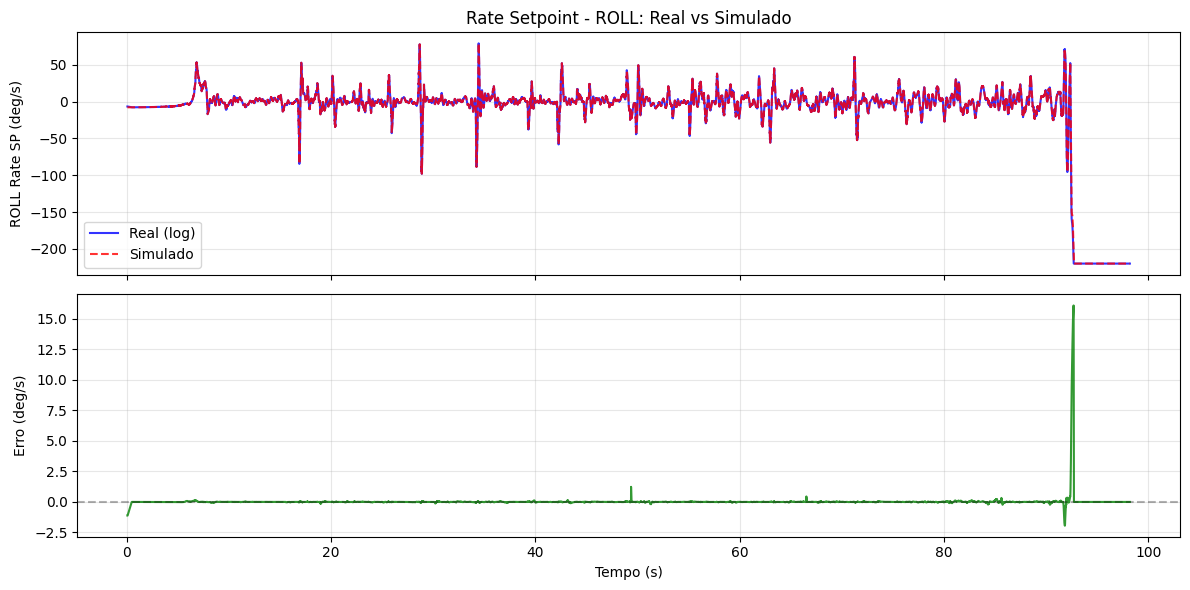

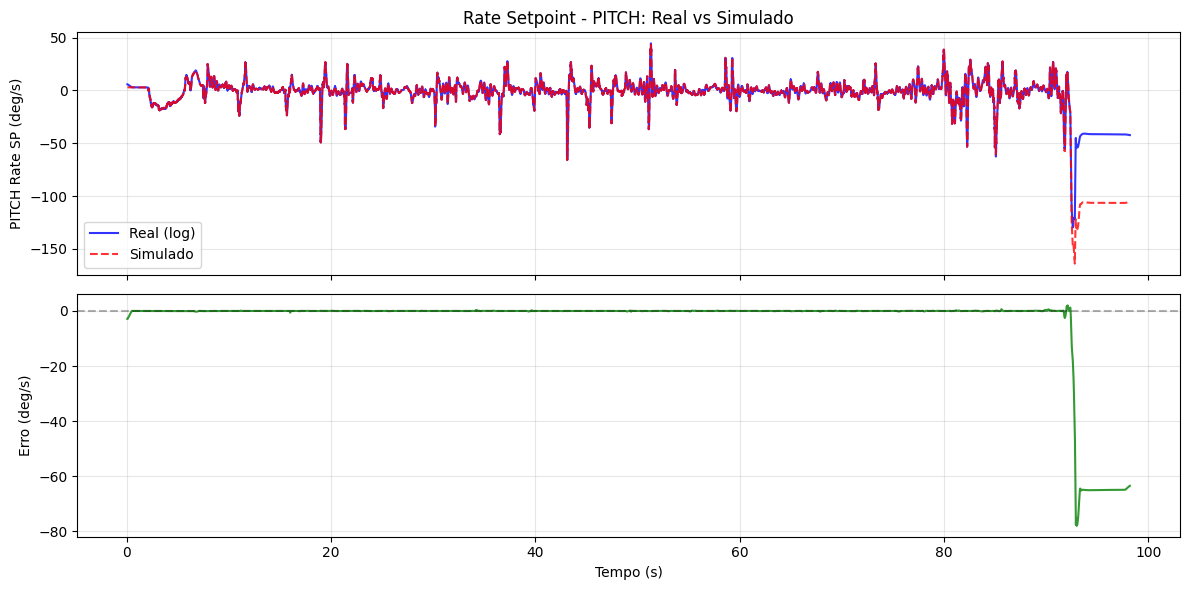

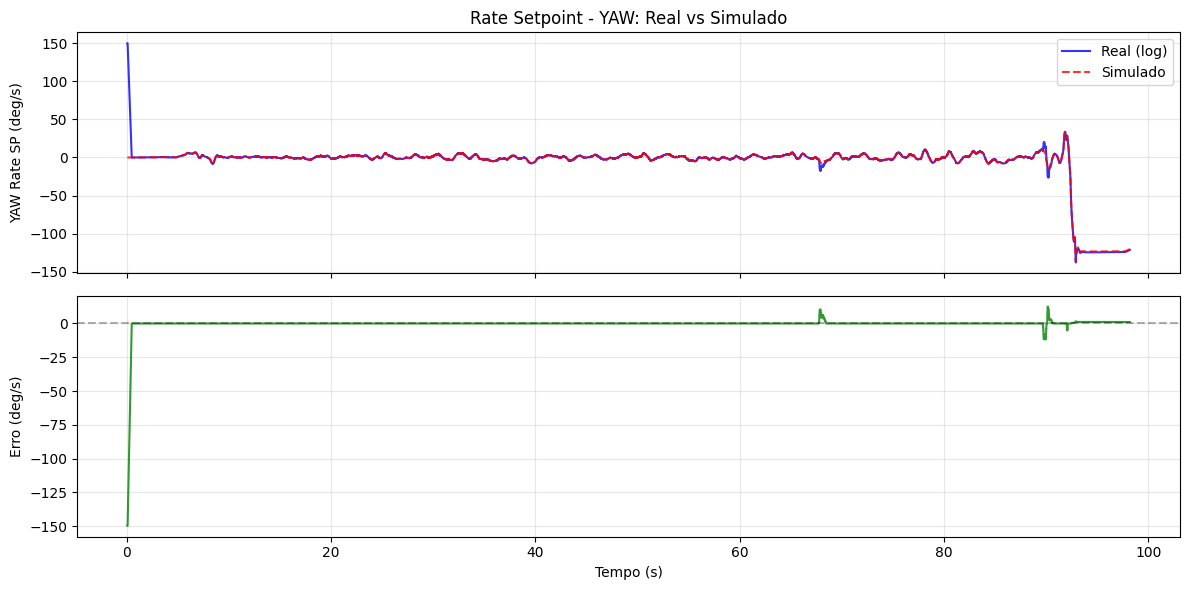

In [29]:
# Compara rate setpoint REAL vs SIMULADO

def plot_rate_sp_comparison(time_sim, rate_sp_sim, rates_sp, axis='roll', time_range=None):
    """Compara rate setpoint real do log com o simulado."""
    axis_map = {'roll': 0, 'pitch': 1, 'yaw': 2}
    idx = axis_map[axis]
    
    sp_col = axis if axis in rates_sp.columns else ['roll', 'pitch', 'yaw'][idx]
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    
    # Aplica range de tempo
    if time_range:
        sim_mask = (time_sim >= time_range[0]) & (time_sim <= time_range[1])
        real_mask = (rates_sp['time_s'] >= time_range[0]) & (rates_sp['time_s'] <= time_range[1])
    else:
        sim_mask = slice(None)
        real_mask = slice(None)
    
    # Converte para deg/s
    sim_deg = np.rad2deg(rate_sp_sim[sim_mask, idx])
    real_deg = np.rad2deg(rates_sp[sp_col][real_mask])
    
    # Plot: Real vs Simulado
    ax1.plot(rates_sp['time_s'][real_mask], real_deg, 'b-', label='Real (log)', alpha=0.8)
    ax1.plot(time_sim[sim_mask], sim_deg, 'r--', label='Simulado', alpha=0.8)
    ax1.set_ylabel(f'{axis.upper()} Rate SP (deg/s)')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_title(f'Rate Setpoint - {axis.upper()}: Real vs Simulado')
    
    # Erro entre real e simulado
    real_interp = np.interp(time_sim[sim_mask], rates_sp['time_s'], np.rad2deg(rates_sp[sp_col]))
    error = sim_deg - real_interp
    
    ax2.plot(time_sim[sim_mask], error, 'g-', alpha=0.8)
    ax2.axhline(y=0, color='k', linestyle='--', alpha=0.3)
    ax2.set_ylabel('Erro (deg/s)')
    ax2.set_xlabel('Tempo (s)')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    return fig

# Plota comparação para os 3 eixos
if attitude is not None and attitude_sp is not None:
    for axis in ['roll', 'pitch', 'yaw']:
        try:
            plot_rate_sp_comparison(time_sim, rate_sp_sim, rates_sp, axis=axis)
            plt.show()
        except Exception as e:
            print(f"Erro plotando {axis}: {e}")

## Otimização dos Ganhos do Attitude Controller

Usa `differential_evolution` (scipy) para encontrar MC_ROLL_P / MC_PITCH_P / MC_YAW_P e rate limits que minimizem o RMSE entre rate setpoint simulado e real.

Sem modelo de planta — só replay da simulação já validada acima.

In [30]:
# Célula 1 — Função de fitness
# param_vec = [roll_P, pitch_P, yaw_P, rollrate_max_deg, pitchrate_max_deg, yawrate_max_deg]

def run_attitude_sim(attitude, attitude_sp, gains, rate_limits):
    """Executa a simulação do attitude controller e retorna (time_base, rate_sp_sim)."""
    time_base = attitude['time_s'].values
    q_sp_w = np.interp(time_base, attitude_sp['time_s'], attitude_sp['q_d[0]'])
    q_sp_x = np.interp(time_base, attitude_sp['time_s'], attitude_sp['q_d[1]'])
    q_sp_y = np.interp(time_base, attitude_sp['time_s'], attitude_sp['q_d[2]'])
    q_sp_z = np.interp(time_base, attitude_sp['time_s'], attitude_sp['q_d[3]'])

    rate_sp_sim = np.zeros((len(time_base), 3))
    for i in range(len(time_base)):
        q_cur = np.array([
            attitude['q[0]'].iloc[i], attitude['q[1]'].iloc[i],
            attitude['q[2]'].iloc[i], attitude['q[3]'].iloc[i],
        ])
        q_des = np.array([q_sp_w[i], q_sp_x[i], q_sp_y[i], q_sp_z[i]])
        rate_sp_sim[i] = attitude_error_to_rate_sp(q_cur, q_des, gains, rate_limits)
    return time_base, rate_sp_sim


def fitness_attitude(param_vec, attitude, attitude_sp, rates_sp):
    """RMSE (rad/s) entre rate setpoint simulado e real, somado nos 3 eixos."""
    gains       = np.array(param_vec[:3])
    rate_limits = np.deg2rad(param_vec[3:])

    time_base, rate_sp_sim = run_attitude_sim(attitude, attitude_sp, gains, rate_limits)

    sp_real = np.column_stack([
        np.interp(time_base, rates_sp['time_s'], rates_sp['roll']),
        np.interp(time_base, rates_sp['time_s'], rates_sp['pitch']),
        np.interp(time_base, rates_sp['time_s'], rates_sp['yaw']),
    ])
    return np.sqrt(np.mean((rate_sp_sim - sp_real) ** 2))


# Parâmetros atuais do log
p0 = [
    ulog.initial_parameters.get('MC_ROLL_P',        5.5),
    ulog.initial_parameters.get('MC_PITCH_P',       5.5),
    ulog.initial_parameters.get('MC_YAW_P',         5.0),
    ulog.initial_parameters.get('MC_ROLLRATE_MAX',  220.0),
    ulog.initial_parameters.get('MC_PITCHRATE_MAX', 220.0),
    ulog.initial_parameters.get('MC_YAWRATE_MAX',   200.0),
]
baseline_rmse = fitness_attitude(p0, attitude, attitude_sp, rates_sp)
print(f"RMSE baseline (ganhos atuais): {np.rad2deg(baseline_rmse):.3f} deg/s")

RMSE baseline (ganhos atuais): 8.933 deg/s


In [31]:
# Célula 2 — Otimização com differential_evolution
from scipy.optimize import differential_evolution

bounds = [
    (1.0,  15.0),  # MC_ROLL_P
    (1.0,  15.0),  # MC_PITCH_P
    (1.0,  10.0),  # MC_YAW_P
    (50.0, 360.0), # MC_ROLLRATE_MAX  (deg/s)
    (50.0, 360.0), # MC_PITCHRATE_MAX (deg/s)
    (50.0, 300.0), # MC_YAWRATE_MAX   (deg/s)
]

result = differential_evolution(
    fitness_attitude,
    bounds,
    args=(attitude, attitude_sp, rates_sp),
    maxiter=150,
    popsize=12,
    tol=1e-5,
    seed=42,
    disp=True,
    workers=1,
)

opt = result.x
print(f"\nRMSE otimizado: {np.rad2deg(result.fun):.3f} deg/s")
print(f"Melhoria:        {(1 - result.fun / baseline_rmse) * 100:.1f}%\n")

labels = ['MC_ROLL_P', 'MC_PITCH_P', 'MC_YAW_P',
          'MC_ROLLRATE_MAX', 'MC_PITCHRATE_MAX', 'MC_YAWRATE_MAX']
print(f"{'Parâmetro':<22} {'Atual':>10}  {'Otimizado':>10}")
print("-" * 46)
for name, orig, val in zip(labels, p0, opt):
    print(f"{name:<22} {orig:>10.4f}  {val:>10.4f}")

differential_evolution step 1: f(x)= 0.12092858003805192
differential_evolution step 2: f(x)= 0.07443216034751436
differential_evolution step 3: f(x)= 0.07443216034751436
differential_evolution step 4: f(x)= 0.07443216034751436
differential_evolution step 5: f(x)= 0.06976193431973587
differential_evolution step 6: f(x)= 0.06947469217802064
differential_evolution step 7: f(x)= 0.06947469217802064
differential_evolution step 8: f(x)= 0.06892322644618773
differential_evolution step 9: f(x)= 0.06738858874757765
differential_evolution step 10: f(x)= 0.06717210288319132
differential_evolution step 11: f(x)= 0.06571392512933455
differential_evolution step 12: f(x)= 0.06571392512933455
differential_evolution step 13: f(x)= 0.06571392512933455
differential_evolution step 14: f(x)= 0.06571392512933455
differential_evolution step 15: f(x)= 0.06571392512933455
differential_evolution step 16: f(x)= 0.06570240944082827
differential_evolution step 17: f(x)= 0.06513910130329821
differential_evolution 

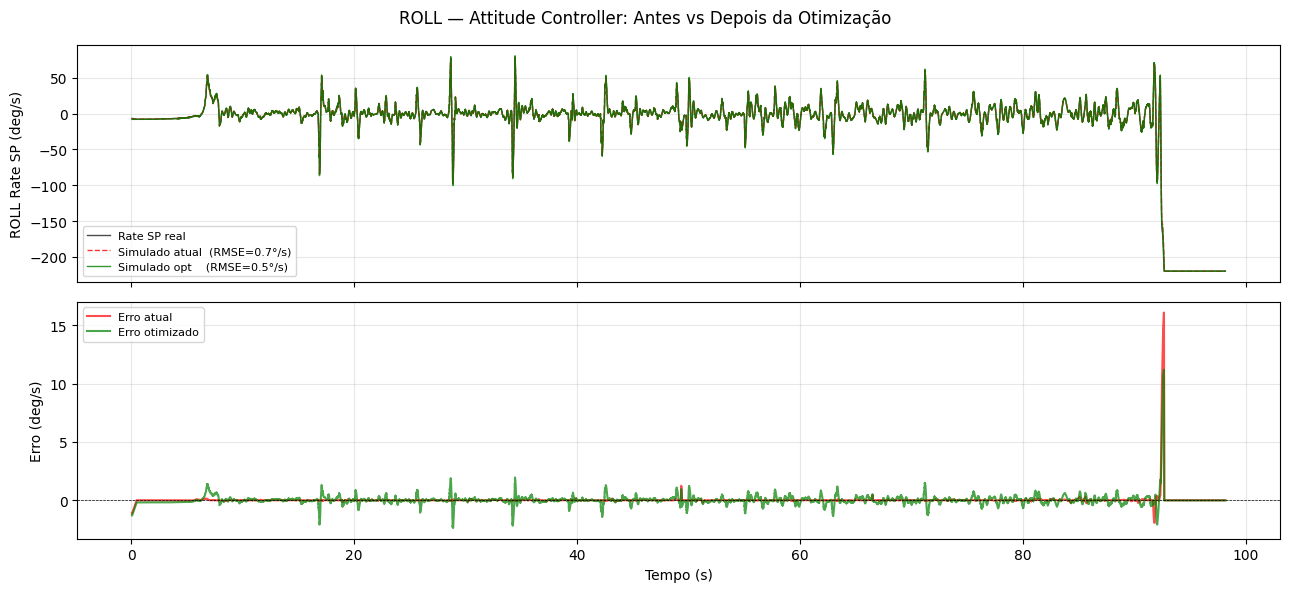

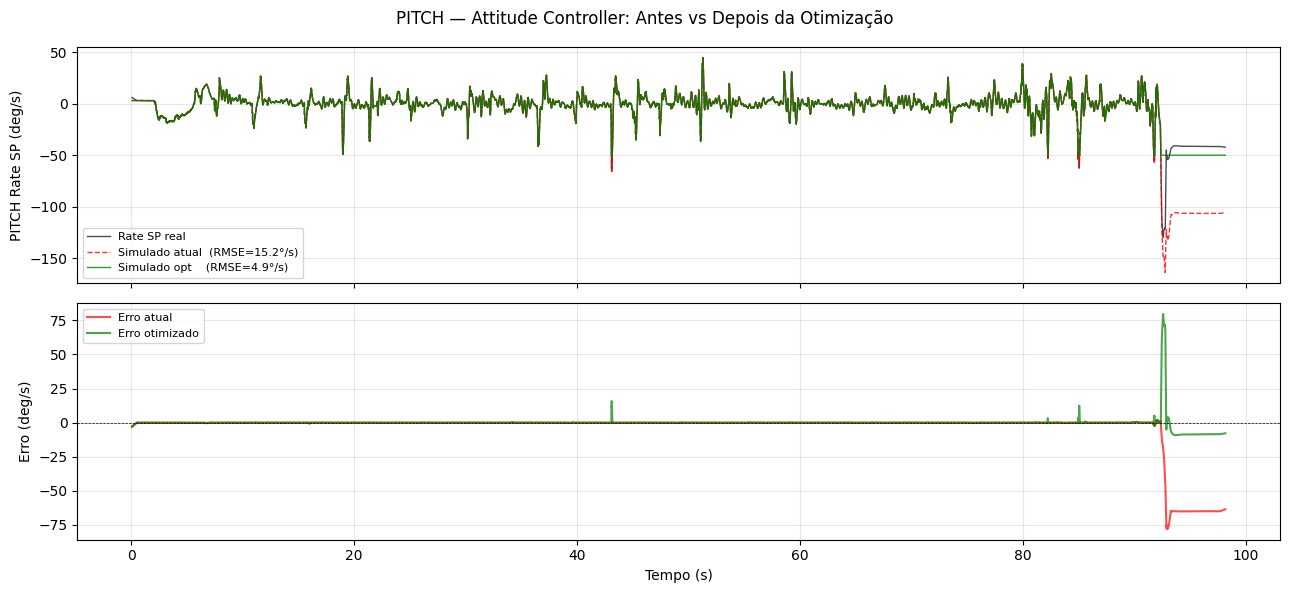

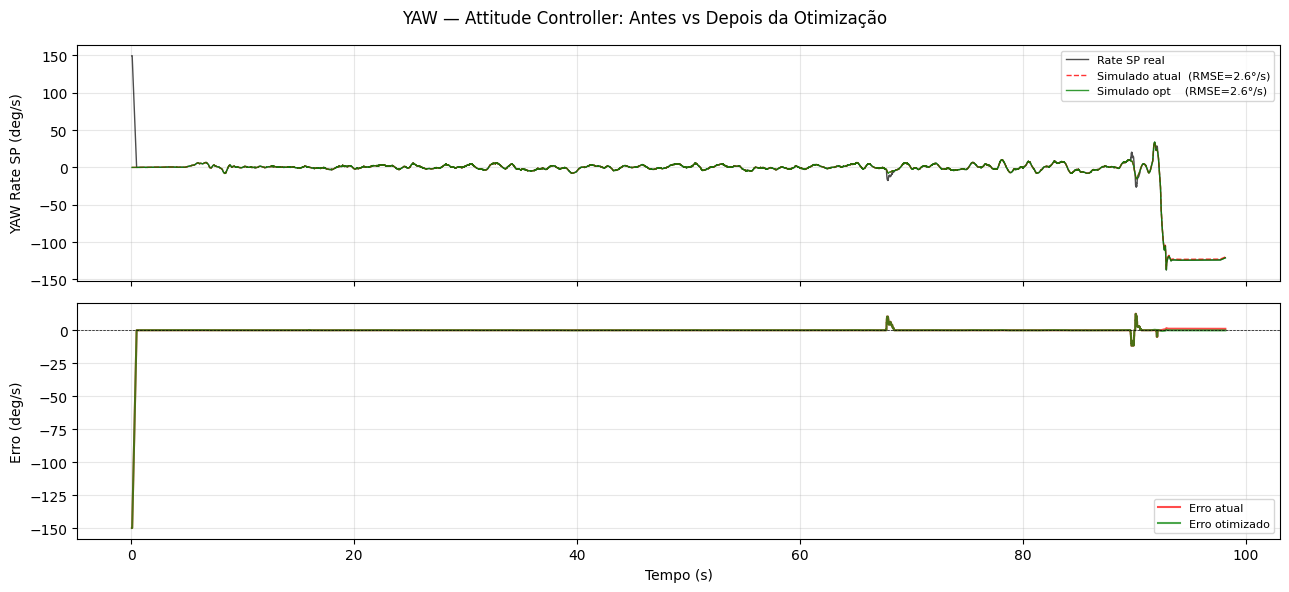

In [32]:
# Célula 3 — Comparação Before / After por eixo
time_base_before, rate_sp_sim_before = run_attitude_sim(
    attitude, attitude_sp,
    gains=np.array(p0[:3]),
    rate_limits=np.deg2rad(p0[3:]),
)

time_base_after, rate_sp_sim_after = run_attitude_sim(
    attitude, attitude_sp,
    gains=np.array(opt[:3]),
    rate_limits=np.deg2rad(opt[3:]),
)

axis_map = {'roll': 0, 'pitch': 1, 'yaw': 2}

for axis, idx in axis_map.items():
    sp_real_t = np.interp(time_base_before, rates_sp['time_s'], rates_sp[axis])

    rmse_before = np.sqrt(np.mean((rate_sp_sim_before[:, idx] - sp_real_t) ** 2))
    rmse_after  = np.sqrt(np.mean((rate_sp_sim_after[:, idx]  - sp_real_t) ** 2))

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
    fig.suptitle(f'{axis.upper()} — Attitude Controller: Antes vs Depois da Otimização', fontsize=12)

    ax1.plot(time_base_before, np.rad2deg(sp_real_t),
             'k-',  label='Rate SP real',                        alpha=0.7, lw=1.0)
    ax1.plot(time_base_before, np.rad2deg(rate_sp_sim_before[:, idx]),
             'r--', label=f'Simulado atual  (RMSE={np.rad2deg(rmse_before):.1f}°/s)', alpha=0.8, lw=1.0)
    ax1.plot(time_base_after,  np.rad2deg(rate_sp_sim_after[:, idx]),
             'g-',  label=f'Simulado opt    (RMSE={np.rad2deg(rmse_after):.1f}°/s)',  alpha=0.8, lw=1.0)
    ax1.set_ylabel(f'{axis.upper()} Rate SP (deg/s)')
    ax1.legend(fontsize=8); ax1.grid(True, alpha=0.3)

    err_before = np.rad2deg(rate_sp_sim_before[:, idx] - sp_real_t)
    err_after  = np.rad2deg(rate_sp_sim_after[:, idx]  - sp_real_t)
    ax2.plot(time_base_before, err_before, 'r-', alpha=0.7, label='Erro atual')
    ax2.plot(time_base_after,  err_after,  'g-', alpha=0.7, label='Erro otimizado')
    ax2.axhline(0, color='k', lw=0.5, ls='--')
    ax2.set_ylabel('Erro (deg/s)'); ax2.set_xlabel('Tempo (s)')
    ax2.legend(fontsize=8); ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

## Resumo: O que entra no Rate Controller

```
┌─────────────────┐     ┌────────────────────┐     ┌─────────────────┐
│ Attitude SP     │────▶│ Attitude Controller│────▶│ Rate Setpoint   │
│ (q_d quaternion)│     │ (P controller)     │     │ (roll/pitch/yaw)│
└─────────────────┘     └────────────────────┘     └────────┬────────┘
                                                            │
┌─────────────────┐     ┌────────────────────┐              ▼
│ Gyroscope       │────▶│ Angular Velocity   │────▶ [Rate Controller]
│ (IMU)           │     │ (medido)           │        (PID)
└─────────────────┘     └────────────────────┘            │
                                                          ▼
                                                    Torque/Mixer
                                                          │
                                                          ▼
                                                      Motores
```

**Para reproduzir o rate setpoint:**
1. Leia `vehicle_attitude` (atual) e `vehicle_attitude_setpoint` (desejado)
2. Calcule erro de atitude via quaternion
3. Multiplique pelos ganhos `MC_ROLL_P`, `MC_PITCH_P`, `MC_YAW_P`
4. Aplique limites `MC_ROLLRATE_MAX`, etc.